# 부산신항 1~5부두 데이터 연결·전처리·점유율 시뮬레이션

이 노트북은 현재까지 확정한 조건을 **처음부터 단계별로 재현**합니다.

분석 순서
1. 원본 CSV 읽기
2. 2022~2025년 기간만 남기기
3. 선명 정리 및 유사 선명 후보 인정
4. `record 출항 ↔ port 출항`, `record 입항 ↔ port 접안`을 각각 ±24시간 이내로 직접 연결
5. `record 1행 ↔ port 여러 행` 형태의 분할후보 추가
6. 접안전시간이 음수인 경우에만 `입항 ↔ 접안` 시각 교환
7. 사용률 계산
8. 선석사용시간 80~115% 시나리오로 점유율·평균 대기시간·평균 재항시간 계산
9. 최대굴곡점 계산 및 한글 그래프 출력

> **사용률 분모는 기간 필터 후 남은 각 port 데이터 건수를 100%로 봅니다.**

> 그래프에서 **평균 대기시간과 평균 재항시간은 서로 다른 색상**으로 표시합니다.

## 0. 공통 준비

In [1]:
from pathlib import Path
import re
from difflib import SequenceMatcher

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

# 프로젝트에서는 ../data, 파일만 따로 받은 경우에는 현재 폴더 사용
DATA = Path('../data')
if not (DATA / 'record(3).csv').exists():
    DATA = Path('.')

# 한글 폰트: Windows에서는 Malgun Gothic, Linux에서는 NanumGothic 사용
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
if 'Malgun Gothic' in available_fonts:
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif 'NanumGothic' in available_fonts:
    plt.rcParams['font.family'] = 'NanumGothic'
else:
    plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

period_start = pd.Timestamp('2022-01-01')
period_end = pd.Timestamp('2026-01-01')  # 종료일 미포함
period_hours = (period_end - period_start).total_seconds() / 3600

PORT_FILES = {
    1: 'port1(2).csv',
    2: 'port2(1).csv',
    3: 'port3(1).csv',
    4: 'port4(1).csv',
    5: 'port5(1).csv',
}

print('데이터 경로:', DATA.resolve())
print('분석 기간:', period_start, '~', period_end, '(종료일 미포함)')

데이터 경로: /mnt/data
분석 기간: 2022-01-01 00:00:00 ~ 2026-01-01 00:00:00 (종료일 미포함)


## 1. CSV 읽기

In [2]:
def read_csv(filename):
    path = DATA / filename
    for encoding in ['utf-8-sig', 'cp949', 'euc-kr']:
        try:
            return pd.read_csv(path, encoding=encoding, low_memory=False)
        except UnicodeDecodeError:
            continue
    raise ValueError(f'인코딩을 확인하세요: {path}')

ports_raw = {pier: read_csv(filename) for pier, filename in PORT_FILES.items()}
record = read_csv('record(3).csv')

for pier in range(1, 6):
    print(f'{pier}부두 원본: {len(ports_raw[pier]):,}건')
print(f'record 원본: {len(record):,}건')

1부두 원본: 2,928건
2부두 원본: 10,943건
3부두 원본: 3,773건
4부두 원본: 5,774건
5부두 원본: 6,156건
record 원본: 19,989건


## 2. 기간 필터 — 2022~2025년만 사용

각 port의 `접안(예정)일시`를 기준으로 2022-01-01 이상, 2026-01-01 미만만 남깁니다. 앞으로 **이 건수를 각 부두의 100% 기준**으로 사용합니다.

In [3]:
ports = {}
period_summary = []

for pier, df in ports_raw.items():
    df = df.copy()
    df['접안시각'] = pd.to_datetime(df['접안(예정)일시'], format='mixed', errors='coerce')
    df['출항시각'] = pd.to_datetime(df['출항(예정)일시'], format='mixed', errors='coerce')

    filtered = df[
        (df['접안시각'] >= period_start)
        & (df['접안시각'] < period_end)
    ].copy().reset_index(drop=True)

    filtered['port_row'] = filtered.index
    ports[pier] = filtered

    period_summary.append({
        '부두': f'{pier}부두',
        '원본건수': len(df),
        '기간밖제외': len(df) - len(filtered),
        '기간필터후건수(100%)': len(filtered),
    })

period_summary = pd.DataFrame(period_summary)
display(period_summary)

,부두,원본건수,기간밖제외,기간필터후건수(100%)
0,1부두,2928,0,2928
1,2부두,10943,4222,6721
2,3부두,3773,3,3770
3,4부두,5774,2355,3419
4,5부두,6156,2287,3869


## 3. record 전처리 + 선명 정리

In [4]:
record = record.copy()
record['입항시각'] = pd.to_datetime(record['입항일시'], format='mixed', errors='coerce')
record['출항시각'] = pd.to_datetime(record['출항일시'], format='mixed', errors='coerce')
record['부두번호'] = pd.to_numeric(
    record['계선장소'].astype('string').str.extract(r'신항\s*(\d+)부두')[0],
    errors='coerce',
)

# 대소문자·공백·하이픈·마침표 등의 차이를 제거
# 예: CMA CGM G. WASHINGTON -> CMACGMGWASHINGTON

def normalize_ship_name(value):
    if pd.isna(value):
        return ''
    value = str(value).upper().strip()
    return re.sub(r'[^A-Z0-9가-힣]+', '', value)

record['연결선명'] = record['선명'].map(normalize_ship_name)

for pier in range(1, 6):
    df = ports[pier]
    name_col = '선박명' if '선박명' in df.columns else '선명'
    df['원본선명'] = df[name_col].astype('string')
    df['연결선명'] = df[name_col].map(normalize_ship_name)
    df['선석번호'] = df['선석'].astype('string')
    df['선석사용시간'] = (
        df['출항시각'] - df['접안시각']
    ).dt.total_seconds() / 3600

print('선명 정리 완료')

선명 정리 완료


## 4. 유사 선명 후보 만들기

완전히 정리된 선명이 같으면 그대로 사용합니다.
그 외에는 `SequenceMatcher` 기준 **90점 이상**인 선명을 같은 선박 후보로 인정합니다.

이 단계는 선명 오탈자나 기호 차이 때문에 연결에서 빠지는 기록을 줄이기 위한 것입니다.

In [5]:
SIMILARITY_THRESHOLD = 90

# RapidFuzz가 있으면 빠르게 사용하고, 없으면 difflib로 동작
try:
    from rapidfuzz import process, fuzz
    USE_RAPIDFUZZ = True
except ImportError:
    USE_RAPIDFUZZ = False


def build_name_candidate_map(port_df, rec_df):
    port_names = port_df['연결선명'].dropna().unique().tolist()
    rec_names = rec_df['연결선명'].dropna().unique().tolist()
    rec_name_set = set(rec_names)

    candidate_map = {}

    for port_name in port_names:
        candidates = []

        # 1) 정리 후 완전 일치
        if port_name in rec_name_set:
            candidates.append(port_name)

        # 2) 유사 선명: 완전 일치가 없는 이름만 탐색
        if not candidates and port_name:
            if USE_RAPIDFUZZ:
                fuzzy_matches = process.extract(
                    port_name,
                    rec_names,
                    scorer=fuzz.ratio,
                    score_cutoff=SIMILARITY_THRESHOLD,
                    limit=5,
                )
                candidates.extend([name for name, score, _ in fuzzy_matches])
            else:
                # RapidFuzz가 없을 때의 fallback
                for rec_name in rec_names:
                    if not rec_name:
                        continue
                    if abs(len(port_name) - len(rec_name)) > 3:
                        continue
                    score = SequenceMatcher(None, port_name, rec_name).ratio() * 100
                    if score >= SIMILARITY_THRESHOLD:
                        candidates.append(rec_name)

        candidate_map[port_name] = list(dict.fromkeys(candidates))

    return candidate_map

name_maps = {}
for pier in range(1, 6):
    rec_pier = record[record['부두번호'] == pier].copy()
    name_maps[pier] = build_name_candidate_map(ports[pier], rec_pier)

print('유사 선명 후보 작성 완료')

유사 선명 후보 작성 완료


## 5. 직접 연결 — 두 시간 조건을 모두 ±24시간 이내로 적용

직접 연결 조건:
- 같은 부두
- 같은 선명 또는 유사 선명 후보
- `record 출항 ↔ port 출항` 차이의 절댓값 ≤ 24시간
- `record 입항 ↔ port 접안` 차이의 절댓값 ≤ 24시간

선석번호는 연결 조건에 사용하지 않습니다.

In [6]:
def direct_match(pier, port_df, record_df, candidate_map):
    rec_pier = record_df[record_df['부두번호'] == pier].copy().reset_index(drop=True)
    rec_pier['record_row'] = rec_pier.index

    # port 선명 -> 연결 가능한 record 선명 후보를 표 형태로 변환
    name_links = []
    for port_name, rec_names in candidate_map.items():
        for rec_name in rec_names:
            name_links.append({
                'port연결선명': port_name,
                'record연결선명': rec_name,
            })
    name_links = pd.DataFrame(name_links)

    if name_links.empty:
        return rec_pier, pd.DataFrame(), port_df['port_row'].tolist(), pd.DataFrame()

    port_base = port_df[
        ['port_row', '연결선명', '접안시각', '출항시각']
    ].rename(columns={'연결선명': 'port연결선명'})

    rec_base = rec_pier[
        ['record_row', '연결선명', '입항시각', '출항시각']
    ].rename(columns={
        '연결선명': 'record연결선명',
        '출항시각': 'record출항시각',
    })

    # 선명 후보를 통해 가능한 port-record 조합 생성
    candidates = (
        port_base
        .merge(name_links, on='port연결선명', how='left')
        .merge(rec_base, on='record연결선명', how='left')
    )

    candidates = candidates.dropna(
        subset=['record_row', '입항시각', 'record출항시각']
    ).copy()

    candidates['출항차이시간'] = (
        candidates['record출항시각'] - candidates['출항시각']
    ).abs().dt.total_seconds() / 3600
    candidates['입항접안차이시간'] = (
        candidates['입항시각'] - candidates['접안시각']
    ).abs().dt.total_seconds() / 3600

    direct = candidates[
        (candidates['출항차이시간'] <= 24)
        & (candidates['입항접안차이시간'] <= 24)
    ].copy()

    direct['차이합'] = direct['출항차이시간'] + direct['입항접안차이시간']
    direct = (
        direct.sort_values(['port_row', '차이합'])
        .drop_duplicates('port_row', keep='first')
    )

    matches = direct[
        ['port_row', 'record_row', '출항차이시간', '입항접안차이시간']
    ].copy()
    matches['record_row'] = matches['record_row'].astype(int)
    matches['연결유형'] = '직접연결'
    matches = matches[
        ['port_row', 'record_row', '연결유형', '출항차이시간', '입항접안차이시간']
    ]

    matched_rows = set(matches['port_row'].tolist())
    unmatched_rows = [
        int(x) for x in port_df['port_row'].tolist()
        if x not in matched_rows
    ]

    return rec_pier, matches.reset_index(drop=True), unmatched_rows, candidates


direct_results = {}
for pier in range(1, 6):
    rec_pier, matches, unmatched, candidates = direct_match(
        pier, ports[pier], record, name_maps[pier]
    )
    direct_results[pier] = {
        'record': rec_pier,
        'matches': matches,
        'unmatched': unmatched,
        'candidates': candidates,
    }
    print(f'{pier}부두 직접연결: {len(matches):,}건 / 미연결: {len(unmatched):,}건')

1부두 직접연결: 2,833건 / 미연결: 95건
2부두 직접연결: 6,187건 / 미연결: 534건
3부두 직접연결: 3,518건 / 미연결: 252건
4부두 직접연결: 2,990건 / 미연결: 429건


5부두 직접연결: 3,396건 / 미연결: 473건


## 6. 분할후보 추가

`record 1행`이 `port 여러 행`으로 나뉜 것으로 보이는 경우를 추가합니다.

한 record에 대해:
- 어떤 port 행은 `입항↔접안 ≤ 24시간`이지만 `출항↔출항 > 24시간`
- 다른 port 행은 `출항↔출항 ≤ 24시간`이지만 `입항↔접안 > 24시간`

이면 두 port 행을 **분할후보**로 추가합니다.

분할후보는 같은 record를 공유하더라도 각각 별도의 port 기록으로 유지합니다.

In [7]:
def find_split_matches(candidates, unmatched_rows, already_used):
    # 직접 연결되지 않은 port 행만 확인
    candidates = candidates[
        candidates['port_row'].isin(unmatched_rows)
    ].copy()

    arr_only = candidates[
        (candidates['입항접안차이시간'] <= 24)
        & (candidates['출항차이시간'] > 24)
    ].copy()
    arr_only['side'] = '입항측'

    dep_only = candidates[
        (candidates['출항차이시간'] <= 24)
        & (candidates['입항접안차이시간'] > 24)
    ].copy()
    dep_only['side'] = '출항측'

    side_candidates = pd.concat([arr_only, dep_only], ignore_index=True)

    if side_candidates.empty:
        return pd.DataFrame(
            columns=['port_row', 'record_row', '연결유형', '출항차이시간', '입항접안차이시간']
        )

    split_rows = []
    used_port_rows = set(already_used)

    for record_row, group in side_candidates.groupby('record_row'):
        arrs = group[group['side'] == '입항측'].sort_values('입항접안차이시간')
        deps = group[group['side'] == '출항측'].sort_values('출항차이시간')

        if arrs.empty or deps.empty:
            continue

        for _, arr_row in arrs.iterrows():
            dep_options = deps[deps['port_row'] != arr_row['port_row']]
            if dep_options.empty:
                continue

            dep_row = dep_options.iloc[0]

            for item, match_type in [
                (arr_row, '분할후보_입항측'),
                (dep_row, '분할후보_출항측'),
            ]:
                port_row = int(item['port_row'])
                if port_row in used_port_rows:
                    continue

                used_port_rows.add(port_row)
                split_rows.append({
                    'port_row': port_row,
                    'record_row': int(record_row),
                    '연결유형': match_type,
                    '출항차이시간': float(item['출항차이시간']),
                    '입항접안차이시간': float(item['입항접안차이시간']),
                })
            break

    return pd.DataFrame(split_rows)


split_results = {}
combined_matches = {}

for pier in range(1, 6):
    direct = direct_results[pier]['matches']
    unmatched = direct_results[pier]['unmatched']
    candidates = direct_results[pier]['candidates']
    used = direct['port_row'].tolist() if not direct.empty else []

    split = find_split_matches(candidates, unmatched, used)

    split_results[pier] = split
    combined_matches[pier] = pd.concat([direct, split], ignore_index=True)

    print(
        f'{pier}부두: 직접 {len(direct):,}건 + '
        f'분할 {len(split):,}건 = {len(combined_matches[pier]):,}건'
    )

1부두: 직접 2,833건 + 분할 0건 = 2,833건


2부두: 직접 6,187건 + 분할 10건 = 6,197건


3부두: 직접 3,518건 + 분할 8건 = 3,526건


4부두: 직접 2,990건 + 분할 2건 = 2,992건
5부두: 직접 3,396건 + 분할 54건 = 3,450건


## 7. 음수 접안전시간 처리 — 음수인 경우에만 입항·접안 swap

먼저

`접안전시간 = port 접안시각 - record 입항시각`

을 계산합니다.

**이 값이 음수일 때만** 두 시각을 서로 바꿉니다.
양수인 기록은 원래 시각을 그대로 유지합니다.

In [8]:
analysis_data = {}
usage_rows = []

for pier in range(1, 6):
    port_df = ports[pier]
    rec_pier = direct_results[pier]['record']
    matches = combined_matches[pier]

    matched = port_df.loc[matches['port_row']].copy().reset_index(drop=True)
    matched = pd.concat(
        [
            matched,
            matches.drop(columns='port_row').reset_index(drop=True),
        ],
        axis=1,
    )

    rec_selected = rec_pier.loc[matched['record_row']].reset_index(drop=True)
    matched['record선명'] = rec_selected['선명'].values
    matched['record입항시각'] = rec_selected['입항시각'].values
    matched['record출항시각'] = rec_selected['출항시각'].values

    # 원래 접안전시간
    matched['원본접안전시간'] = (
        matched['접안시각'] - matched['record입항시각']
    ).dt.total_seconds() / 3600

    negative = matched['원본접안전시간'] < 0

    # 음수인 행만 입항과 접안 시각 교환
    matched['분석입항시각'] = matched['record입항시각']
    matched['분석접안시각'] = matched['접안시각']

    matched.loc[negative, '분석입항시각'] = matched.loc[negative, '접안시각']
    matched.loc[negative, '분석접안시각'] = matched.loc[negative, 'record입항시각']

    matched['접안전시간'] = (
        matched['분석접안시각'] - matched['분석입항시각']
    ).dt.total_seconds() / 3600

    matched['선석사용시간_분석'] = (
        matched['출항시각'] - matched['분석접안시각']
    ).dt.total_seconds() / 3600

    matched['재항시간_분석'] = (
        matched['record출항시각'] - matched['분석입항시각']
    ).dt.total_seconds() / 3600

    matched['사용가능'] = (
        (matched['접안전시간'] >= 0)
        & (matched['선석사용시간_분석'] > 0)
        & (matched['재항시간_분석'] > 0)
    )

    final = matched[matched['사용가능']].copy()
    analysis_data[pier] = final

    usage_rows.append({
        '부두': f'{pier}부두',
        '기간필터후건수(100%)': len(port_df),
        '직접연결': len(direct_results[pier]['matches']),
        '분할후보추가': len(split_results[pier]),
        '음수swap건수': int(negative.sum()),
        '최종사용건수': len(final),
        '사용률(%)': len(final) / len(port_df) * 100,
    })

usage_summary = pd.DataFrame(usage_rows)
display(usage_summary.round({'사용률(%)': 2}))

,부두,기간필터후건수(100%),직접연결,분할후보추가,음수swap건수,최종사용건수,사용률(%)
0,1부두,2928,2833,0,70,2833,96.76
1,2부두,6721,6187,10,1780,6197,92.20
2,3부두,3770,3518,8,1510,3526,93.53
3,4부두,3419,2990,2,332,2992,87.51
4,5부두,3869,3396,54,49,3450,89.17


## 8. 선석점유율 시뮬레이션 준비

선석사용시간을 80%~115%까지 1%p씩 변화시키면서 각 부두의 점유율·평균 대기시간·평균 재항시간을 계산합니다.

- 점유율 = 조정된 선석사용시간 합 ÷ (선석 수 × 분석기간 전체시간) × 100
- 평균 대기시간 = 선박이 분석입항시각 이후 실제 작업을 시작할 때까지 기다린 시간
- 평균 재항시간 = 대기시간 + 조정된 선석사용시간

In [9]:
def run_scenario(df, scale):
    working = df.copy()
    working['조정선석사용시간'] = working['선석사용시간_분석'] * scale

    berth_count = working['선석번호'].nunique()
    occupancy = (
        working['조정선석사용시간'].sum()
        / (berth_count * period_hours)
        * 100
    )

    waiting_times = []
    stay_times = []

    for berth, group in working.groupby('선석번호'):
        group = group.sort_values('분석입항시각')
        berth_free_time = None

        for _, row in group.iterrows():
            arrival = row['분석입항시각']
            service_hours = row['조정선석사용시간']

            if berth_free_time is None or arrival >= berth_free_time:
                start = arrival
            else:
                start = berth_free_time

            waiting = (start - arrival).total_seconds() / 3600
            finish = start + pd.Timedelta(hours=service_hours)
            berth_free_time = finish

            waiting_times.append(waiting)
            stay_times.append(waiting + service_hours)

    return {
        '선석점유율': occupancy,
        '평균대기시간': np.mean(waiting_times),
        '평균재항시간': np.mean(stay_times),
    }

scales = np.arange(0.80, 1.151, 0.01)
scenario_results = {}

for pier in range(1, 6):
    rows = []
    for scale in scales:
        result = run_scenario(analysis_data[pier], scale)
        result['작업시간배율(%)'] = scale * 100
        rows.append(result)

    scenario_results[pier] = pd.DataFrame(rows)

print('시뮬레이션 완료')

시뮬레이션 완료


## 9. 최대굴곡점 계산

평균 대기시간 곡선에서 곡률(curvature)이 가장 큰 지점을 최대굴곡점으로 잡습니다.
즉, **점유율 증가에 따라 대기시간 증가 모양이 가장 크게 꺾이는 지점**입니다.

In [10]:
def find_max_bend(df):
    df = df.sort_values('선석점유율').reset_index(drop=True)

    x = df['선석점유율'].to_numpy(dtype=float)
    y = df['평균대기시간'].to_numpy(dtype=float)

    first_derivative = np.gradient(y, x)
    second_derivative = np.gradient(first_derivative, x)

    curvature = (
        np.abs(second_derivative)
        / np.power(1 + first_derivative ** 2, 1.5)
    )

    idx = int(np.nanargmax(curvature))

    return {
        'index': idx,
        '최대굴곡점_점유율': x[idx],
        '최대굴곡점_평균대기시간': y[idx],
        '최대굴곡점_평균재항시간': df.loc[idx, '평균재항시간'],
        '작업시간배율(%)': df.loc[idx, '작업시간배율(%)'],
    }

bend_rows = []
for pier in range(1, 6):
    bend = find_max_bend(scenario_results[pier])
    bend_rows.append({
        '부두': f'{pier}부두',
        **{k: v for k, v in bend.items() if k != 'index'}
    })

bend_summary = pd.DataFrame(bend_rows)
display(bend_summary.round(2))

,부두,최대굴곡점_점유율,최대굴곡점_평균대기시간,최대굴곡점_평균재항시간,작업시간배율(%)
0,1부두,81.67,1.55,31.88,106.0
1,2부두,86.54,2.99,27.47,106.0
2,3부두,59.18,1.75,25.30,107.0
3,4부두,70.27,11.80,36.50,111.0
4,5부두,64.17,1.65,27.74,108.0


## 10. 부두별 그래프

그래프 구성:
- **파란색**: 평균 대기시간 — 왼쪽 y축
- **주황색**: 평균 재항시간 — 오른쪽 y축
- **검은 점선**: 최대굴곡점 점유율

그래프 제목·축·범례는 모두 한글로 표시합니다.

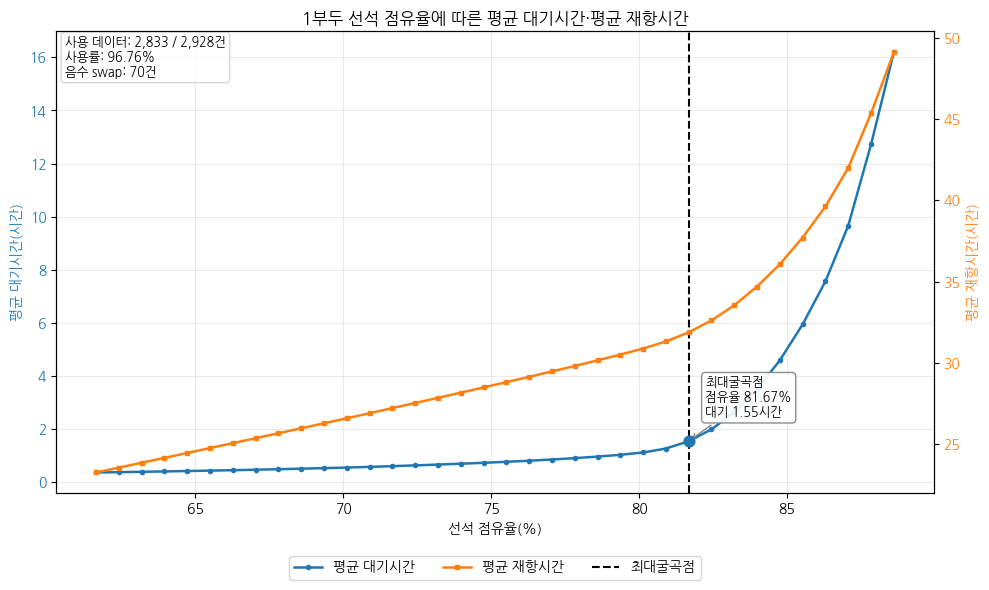

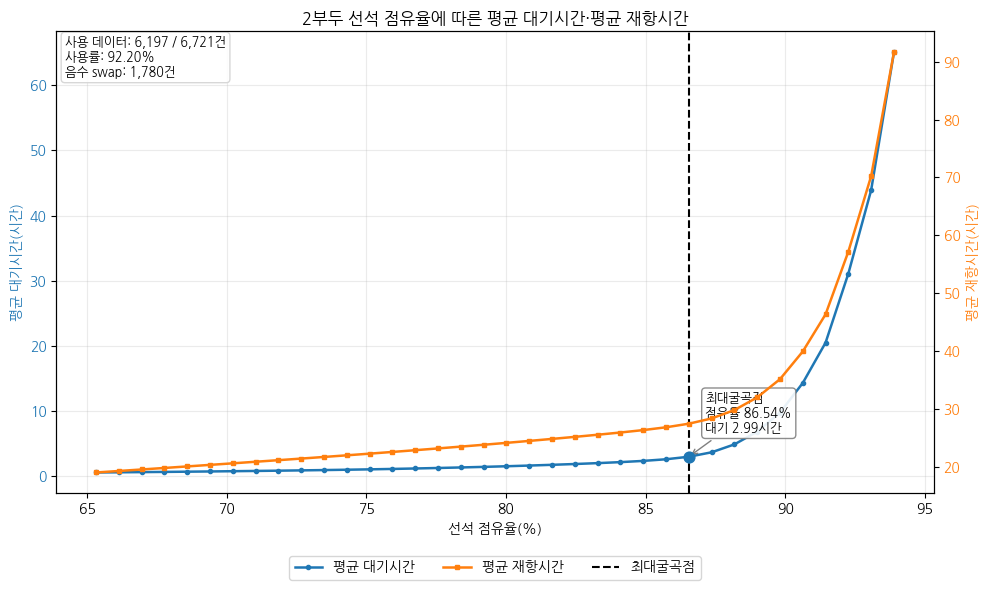

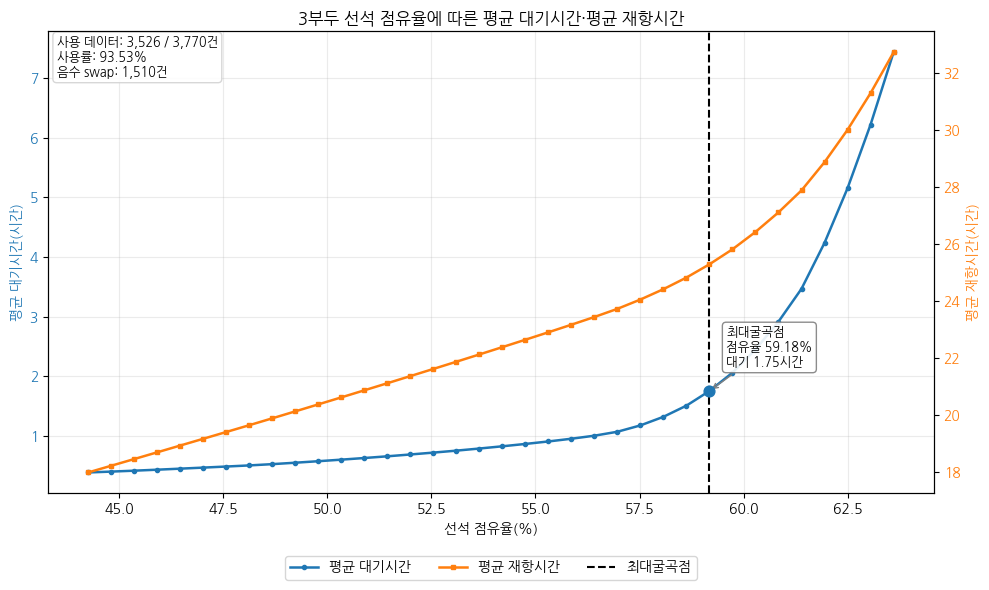

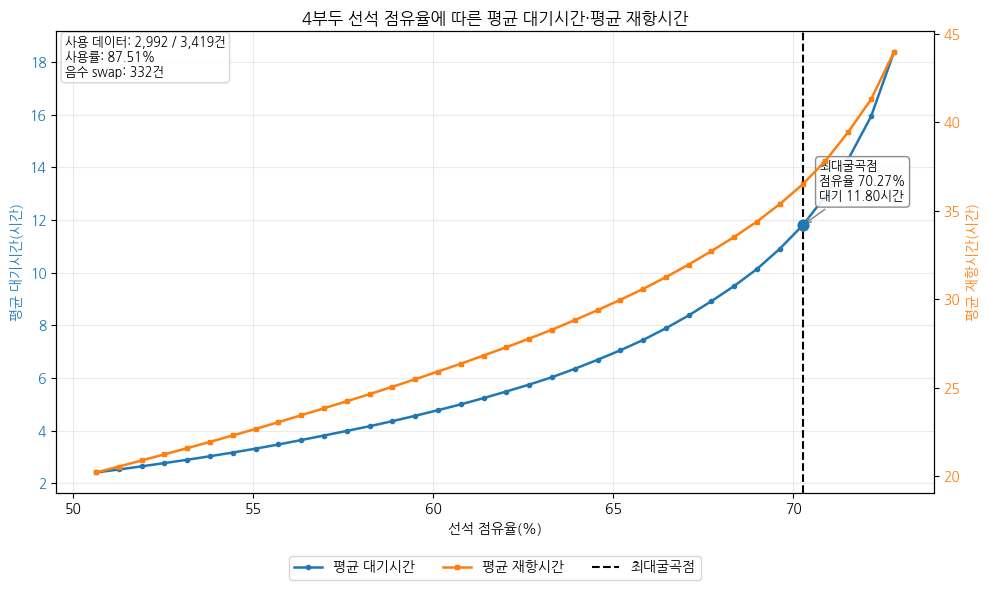

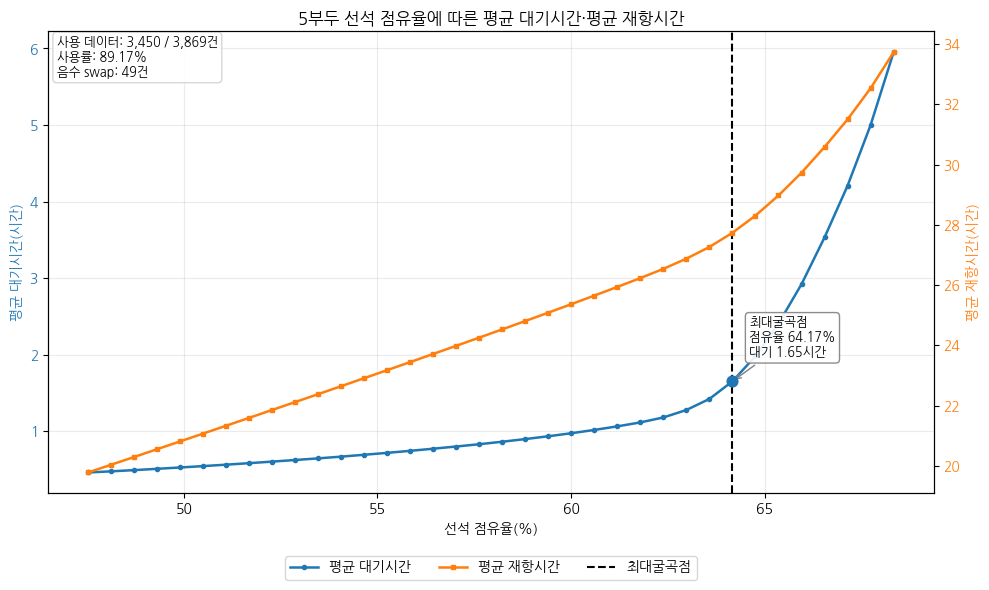

In [11]:
WAIT_COLOR = 'tab:blue'
STAY_COLOR = 'tab:orange'
BEND_COLOR = 'black'

for pier in range(1, 6):
    df = scenario_results[pier]
    bend = find_max_bend(df)
    usage = usage_summary[usage_summary['부두'] == f'{pier}부두'].iloc[0]

    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax2 = ax1.twinx()

    wait_line, = ax1.plot(
        df['선석점유율'],
        df['평균대기시간'],
        color=WAIT_COLOR,
        marker='o',
        markersize=3,
        linewidth=1.8,
        label='평균 대기시간',
    )

    stay_line, = ax2.plot(
        df['선석점유율'],
        df['평균재항시간'],
        color=STAY_COLOR,
        marker='s',
        markersize=3,
        linewidth=1.8,
        label='평균 재항시간',
    )

    bend_line = ax1.axvline(
        bend['최대굴곡점_점유율'],
        color=BEND_COLOR,
        linestyle='--',
        linewidth=1.5,
        label='최대굴곡점',
    )

    ax1.scatter(
        bend['최대굴곡점_점유율'],
        bend['최대굴곡점_평균대기시간'],
        color=WAIT_COLOR,
        s=60,
        zorder=5,
    )

    ax1.annotate(
        f"최대굴곡점\n"
        f"점유율 {bend['최대굴곡점_점유율']:.2f}%\n"
        f"대기 {bend['최대굴곡점_평균대기시간']:.2f}시간",
        xy=(
            bend['최대굴곡점_점유율'],
            bend['최대굴곡점_평균대기시간'],
        ),
        xytext=(12, 18),
        textcoords='offset points',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='gray', alpha=0.9),
        arrowprops=dict(arrowstyle='->', color='gray'),
    )

    ax1.set_title(f'{pier}부두 선석 점유율에 따른 평균 대기시간·평균 재항시간')
    ax1.set_xlabel('선석 점유율(%)')
    ax1.set_ylabel('평균 대기시간(시간)', color=WAIT_COLOR)
    ax2.set_ylabel('평균 재항시간(시간)', color=STAY_COLOR)
    ax1.tick_params(axis='y', labelcolor=WAIT_COLOR)
    ax2.tick_params(axis='y', labelcolor=STAY_COLOR)
    ax1.grid(alpha=0.25)

    info = (
        f"사용 데이터: {int(usage['최종사용건수']):,} / "
        f"{int(usage['기간필터후건수(100%)']):,}건\n"
        f"사용률: {usage['사용률(%)']:.2f}%\n"
        f"음수 swap: {int(usage['음수swap건수']):,}건"
    )
    ax1.text(
        0.01, 0.99, info,
        transform=ax1.transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='lightgray', alpha=0.9),
    )

    ax1.legend(
        [wait_line, stay_line, bend_line],
        ['평균 대기시간', '평균 재항시간', '최대굴곡점'],
        loc='upper center',
        bbox_to_anchor=(0.5, -0.12),
        ncol=3,
    )

    plt.tight_layout()
    plt.show()

## 11. 1~5부두 그래프 한 번에 확인

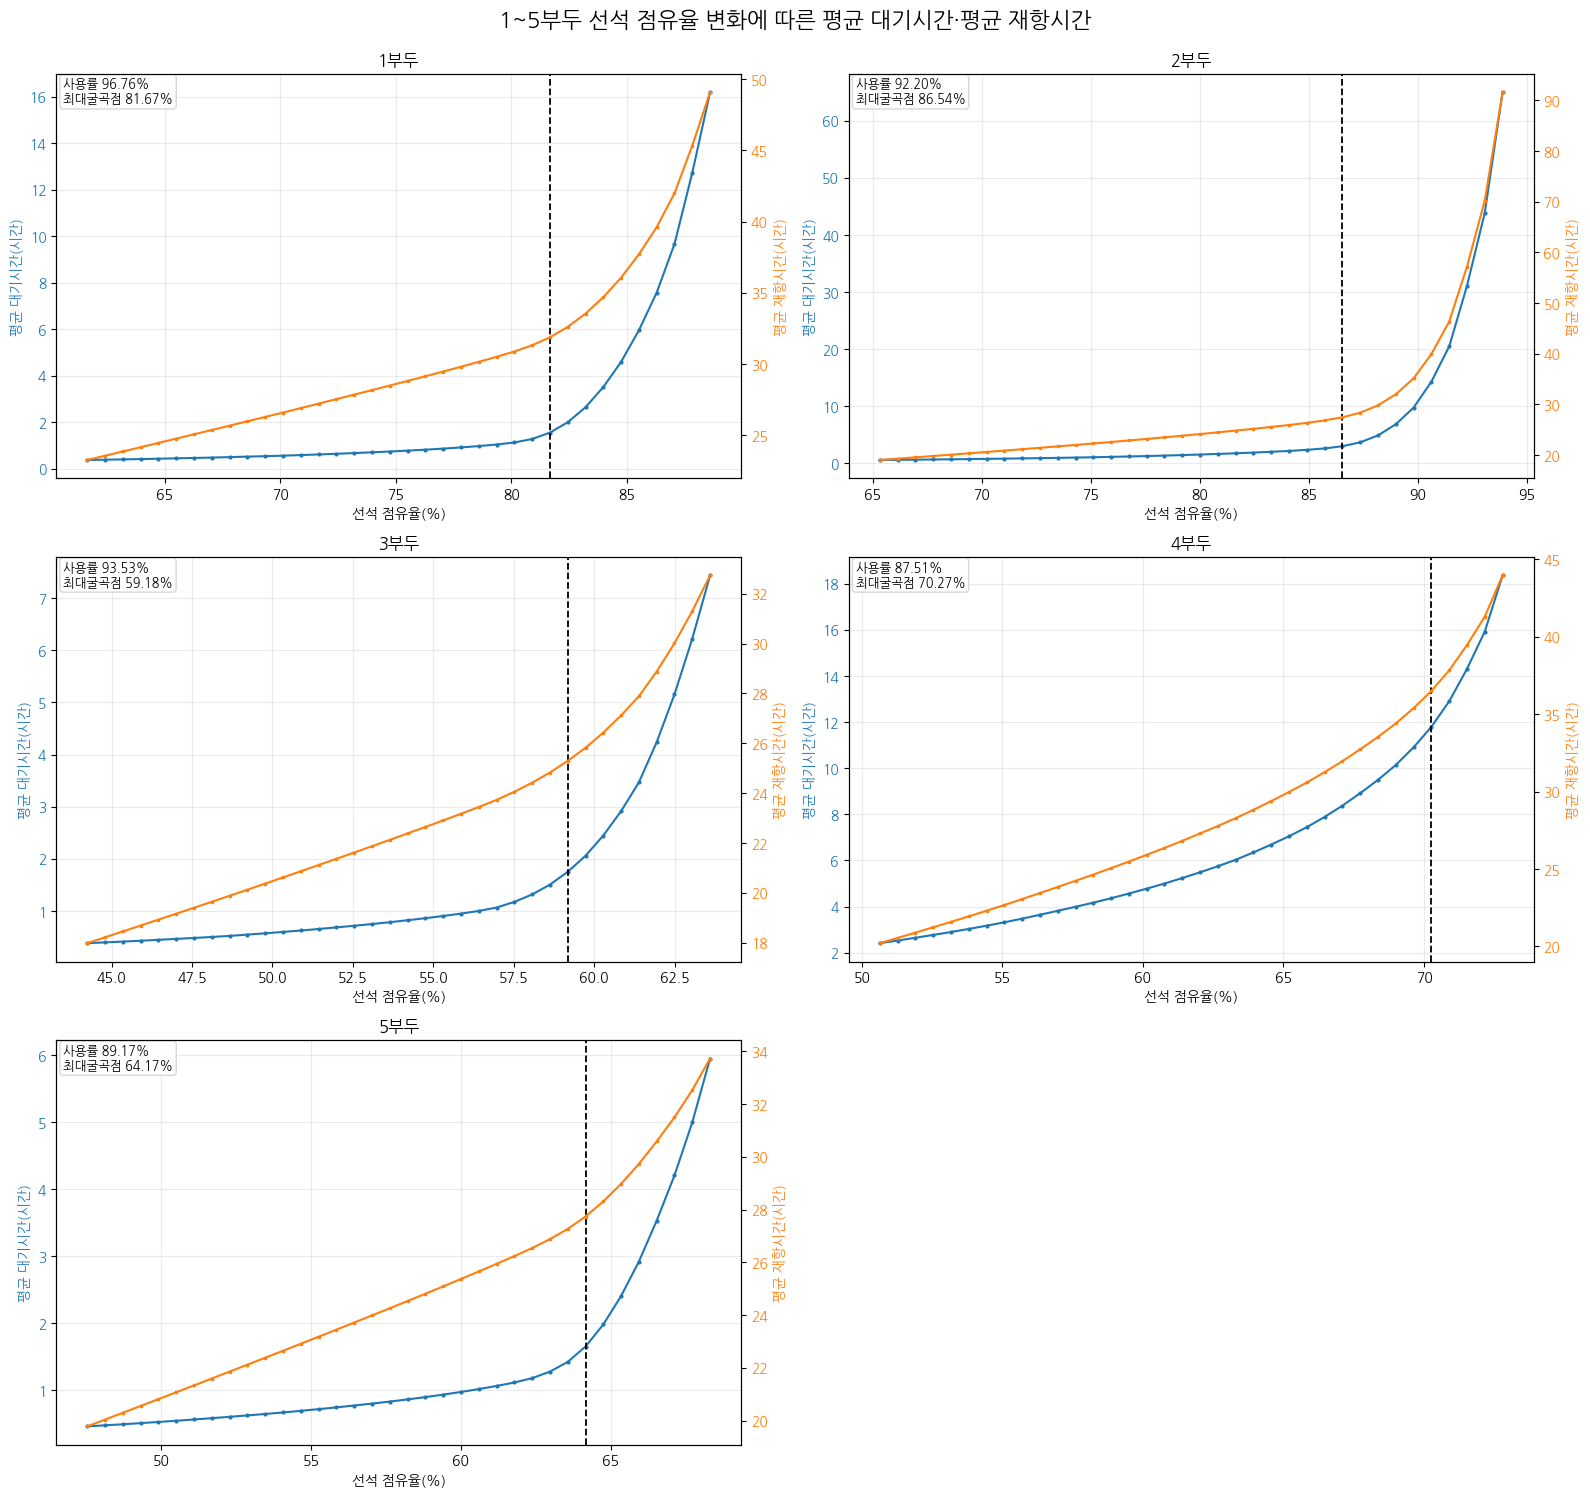

In [12]:
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
axes = axes.ravel()

for i, pier in enumerate(range(1, 6)):
    ax1 = axes[i]
    ax2 = ax1.twinx()

    df = scenario_results[pier]
    bend = find_max_bend(df)
    usage = usage_summary[usage_summary['부두'] == f'{pier}부두'].iloc[0]

    ax1.plot(
        df['선석점유율'], df['평균대기시간'],
        color=WAIT_COLOR, marker='o', markersize=2,
    )
    ax2.plot(
        df['선석점유율'], df['평균재항시간'],
        color=STAY_COLOR, marker='s', markersize=2,
    )
    ax1.axvline(
        bend['최대굴곡점_점유율'],
        color=BEND_COLOR, linestyle='--', linewidth=1.3,
    )

    ax1.set_title(f'{pier}부두')
    ax1.set_xlabel('선석 점유율(%)')
    ax1.set_ylabel('평균 대기시간(시간)', color=WAIT_COLOR)
    ax2.set_ylabel('평균 재항시간(시간)', color=STAY_COLOR)
    ax1.tick_params(axis='y', labelcolor=WAIT_COLOR)
    ax2.tick_params(axis='y', labelcolor=STAY_COLOR)
    ax1.grid(alpha=0.25)

    ax1.text(
        0.01, 0.99,
        f"사용률 {usage['사용률(%)']:.2f}%\n"
        f"최대굴곡점 {bend['최대굴곡점_점유율']:.2f}%",
        transform=ax1.transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='lightgray', alpha=0.9),
    )

axes[-1].axis('off')
fig.suptitle(
    '1~5부두 선석 점유율 변화에 따른 평균 대기시간·평균 재항시간',
    fontsize=16,
    y=0.995,
)
plt.tight_layout()
plt.show()

## 12. 최종 요약

`usage_summary`에는 부두별 사용률, `bend_summary`에는 부두별 최대굴곡점이 정리되어 있습니다.

In [13]:
print('부두별 사용률')
display(usage_summary.round({'사용률(%)': 2}))

print('부두별 최대굴곡점')
display(bend_summary.round(2))

부두별 사용률


,부두,기간필터후건수(100%),직접연결,분할후보추가,음수swap건수,최종사용건수,사용률(%)
0,1부두,2928,2833,0,70,2833,96.76
1,2부두,6721,6187,10,1780,6197,92.20
2,3부두,3770,3518,8,1510,3526,93.53
3,4부두,3419,2990,2,332,2992,87.51
4,5부두,3869,3396,54,49,3450,89.17


부두별 최대굴곡점


,부두,최대굴곡점_점유율,최대굴곡점_평균대기시간,최대굴곡점_평균재항시간,작업시간배율(%)
0,1부두,81.67,1.55,31.88,106.0
1,2부두,86.54,2.99,27.47,106.0
2,3부두,59.18,1.75,25.30,107.0
3,4부두,70.27,11.80,36.50,111.0
4,5부두,64.17,1.65,27.74,108.0
